<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h2>تمرین سوم: بخش <span dir='ltr'>KNN</span></h2>

<p>
در این نوت‌بوک، الگوریتم <span dir='ltr'>KNN</span> برای تشخیص نوع گل‌های دیتاست <span dir='ltr'>Iris</span> پیاده‌سازی شده. هدف مدل اینه که با استفاده از چهار ویژگی اندازه‌گیری‌شده هر گل، نوع آن را بین سه کلاس <span dir='ltr'>Setosa</span>، <span dir='ltr'>Versicolor</span> و <span dir='ltr'>Virginica</span> پیش‌بینی کنه.
</p>

<p>
در بخش اول، الگوریتم <span dir='ltr'>KNN</span> بدون استفاده از مدل آماده <span dir='ltr'>sklearn</span> نوشته شده. فاصله اقلیدسی به صورت دستی حساب میشه، برای هر نمونه تست نزدیک‌ترین همسایه‌ها پیدا میشن و کلاس نهایی با رای اکثریت تعیین میشه.
</p>

<p>
در بخش‌های بعدی، اثر مقدار <span dir='ltr'>k</span> روی دقت بررسی میشه، نتیجه مدل دستی با مدل خواسته‌شده در <span dir='ltr'>Scikit-Learn</span> مقایسه میشه و در پایان معیارهای فاصله مختلف مثل <span dir='ltr'>Euclidean</span>، <span dir='ltr'>Manhattan</span> و <span dir='ltr'>Minkowski</span> بررسی میشن.
</p>

</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۱. آماده‌سازی داده و نرمال‌سازی</h3>

<p>
در این بخش دیتاست <span dir='ltr'>Iris</span> از <span dir='ltr'>sklearn.datasets</span> خوانده میشه. این دیتاست شامل چهار ویژگی عددی برای هر گل است: طول کاسبرگ، عرض کاسبرگ، طول گلبرگ و عرض گلبرگ. خروجی هم نوع گل است که یکی از سه کلاس دیتاست را نشان میده.
</p>

<p>
داده‌ها با نسبت <span dir='ltr'>80/20</span> به بخش آموزش و آزمون تقسیم میشن. تقسیم داده به صورت <span dir='ltr'>stratified</span> انجام شده تا نسبت هر سه کلاس در داده آموزش و تست تقریبا برابر بمونه و ارزیابی مدل منصفانه‌تر باشه.
</p>

<p>
نرمال‌سازی در <span dir='ltr'>KNN</span> مهمه، چون این الگوریتم مستقیما با فاصله بین نمونه‌ها کار می‌کنه. اگر یک ویژگی مقیاس بزرگ‌تری داشته باشه، اثر بیشتری روی فاصله می‌ذاره و ممکنه نتیجه مدل را به سمت همان ویژگی ببره. برای جلوگیری از این مشکل، میانگین و انحراف معیار فقط از داده آموزش حساب شده و سپس همان تبدیل روی داده آموزش و تست اعمال شده.
</p>

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

RANDOM_STATE = 17
TEST_SIZE = 0.20
K_VALUES = [1, 3, 5, 7, 11]

iris = load_iris()
X = iris.data.astype(float)
y = iris.target.astype(int)
feature_names = iris.feature_names
target_names = iris.target_names

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

train_mean = X_train_raw.mean(axis=0)
train_std = X_train_raw.std(axis=0)

X_train = (X_train_raw - train_mean) / train_std
X_test = (X_test_raw - train_mean) / train_std

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Class names:", list(target_names))
print("Train class counts:", np.bincount(y_train))
print("Test class counts:", np.bincount(y_test))

normalization_table = pd.DataFrame({
    "Feature": feature_names,
    "Train Mean": train_mean,
    "Train Std": train_std
})

display(normalization_table.round(4))

Train shape: (120, 4)
Test shape: (30, 4)
Class names: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Train class counts: [40 40 40]
Test class counts: [10 10 10]


,Feature,Train Mean,Train Std
0,sepal length (cm),5.8383,0.8293
1,sepal width (cm),3.0475,0.4309
2,petal length (cm),3.7675,1.7738
3,petal width (cm),1.1950,0.7588


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>تفسیر آماده‌سازی داده‌ها</h3>

<p>
خروجی بالا نشان میده که داده‌ها به <span dir='ltr'>120</span> نمونه آموزش و <span dir='ltr'>30</span> نمونه تست تقسیم شدن. در هر سه کلاس، تعداد نمونه‌های آموزش برابر با <span dir='ltr'>40</span> و تعداد نمونه‌های تست برابر با <span dir='ltr'>10</span> است. این یعنی تقسیم داده‌ها متوازن انجام شده و هر سه نوع گل در آموزش و تست حضور دارن.
</p>

<p>
جدول میانگین و انحراف معیار هم نشان میده که ویژگی‌ها در مقیاس‌های متفاوتی قرار داشتن. برای همین نرمال‌سازی قبل از اجرای <span dir='ltr'>KNN</span> لازم بوده تا هیچ ویژگی فقط به خاطر مقیاس بزرگ‌تر، نقش بیشتری در فاصله پیدا نکنه.
</p>

</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۲. پیاده‌سازی دستی الگوریتم <span dir='ltr'>KNN</span></h3>

<p>
در این بخش تابع فاصله اقلیدسی و خود الگوریتم <span dir='ltr'>KNN</span> به صورت دستی نوشته شده. برای هر نمونه تست، فاصله آن با تمام نمونه‌های آموزش محاسبه میشه. سپس <span dir='ltr'>k</span> نمونه‌ای که کمترین فاصله را دارن انتخاب میشن.
</p>

<p>
بعد از پیدا کردن نزدیک‌ترین همسایه‌ها، کلاس نهایی با رای اکثریت تعیین میشه. یعنی هر کلاسی که بین همسایه‌های انتخاب‌شده بیشتر تکرار شده باشه، به عنوان خروجی مدل انتخاب میشه.
</p>

<p>
برای اینکه نتیجه قابل تکرار باشه، اگر بین چند کلاس رای برابر پیش بیاد، کلاسی انتخاب میشه که مجموع فاصله همسایه‌های آن کمتر باشه. این کار کمک می‌کنه در حالت مساوی، کلاسی انتخاب بشه که از نظر فاصله به نمونه تست نزدیک‌تره.
</p>

</div>

,k,Accuracy
0,1,0.9667
1,3,0.9667
2,5,1.0000
3,7,0.9667
4,11,0.9333


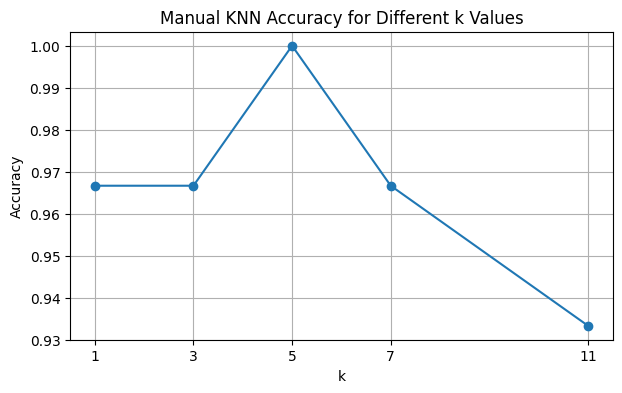

Best k: 5
Best manual accuracy: 1.0


In [2]:
def euclidean_distances(X_query, X_reference):
    diff = X_query[:, np.newaxis, :] - X_reference[np.newaxis, :, :]
    return np.sqrt(np.sum(diff ** 2, axis=2))


def knn_predict(X_train, y_train, X_test, k=5, metric="euclidean", p=2):
    if metric == "euclidean":
        distances = euclidean_distances(X_test, X_train)
    elif metric == "manhattan":
        diff = np.abs(X_test[:, np.newaxis, :] - X_train[np.newaxis, :, :])
        distances = np.sum(diff, axis=2)
    elif metric == "minkowski":
        diff = np.abs(X_test[:, np.newaxis, :] - X_train[np.newaxis, :, :])
        distances = np.sum(diff ** p, axis=2) ** (1 / p)
    else:
        raise ValueError("metric must be euclidean, manhattan, or minkowski")

    predictions = []

    for row_distances in distances:
        neighbor_indices = np.argsort(row_distances)[:k]
        neighbor_labels = y_train[neighbor_indices]
        labels, counts = np.unique(neighbor_labels, return_counts=True)

        max_count = counts.max()
        tied_labels = labels[counts == max_count]

        if len(tied_labels) == 1:
            predictions.append(tied_labels[0])
        else:
            tied_distances = []
            for label in tied_labels:
                label_mask = neighbor_labels == label
                tied_distances.append(np.sum(row_distances[neighbor_indices][label_mask]))
            predictions.append(tied_labels[np.argmin(tied_distances)])

    return np.array(predictions)


def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)


manual_rows = []

for k in K_VALUES:
    y_pred = knn_predict(X_train, y_train, X_test, k=k)
    manual_rows.append({
        "k": k,
        "Accuracy": accuracy(y_test, y_pred)
    })

manual_results = pd.DataFrame(manual_rows)
display(manual_results.round(4))

plt.figure(figsize=(7, 4))
plt.plot(manual_results["k"], manual_results["Accuracy"], marker="o")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Manual KNN Accuracy for Different k Values")
plt.xticks(K_VALUES)
plt.grid(True)
plt.show()

best_k = int(manual_results.loc[manual_results["Accuracy"].idxmax(), "k"])
best_manual_accuracy = float(manual_results["Accuracy"].max())

print("Best k:", best_k)
print("Best manual accuracy:", round(best_manual_accuracy, 4))

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>تفسیر نتیجه بخش اول</h3>

<p>
طبق جدول و نمودار بالا، مقدار <span dir='ltr'>k</span> روی دقت مدل اثر دارد. وقتی <span dir='ltr'>k</span> خیلی کوچک باشد، مدل بیشتر به نزدیک‌ترین نمونه وابسته میشه و ممکنه نسبت به نویز حساس‌تر باشه. وقتی <span dir='ltr'>k</span> خیلی بزرگ‌تر شود، تصمیم مدل نرم‌تر میشه، ولی ممکنه نمونه‌های دورتر هم وارد رای‌گیری بشن و دقت کمتر شود.
</p>

<p>
در این اجرا، برای مقدارهای <span dir='ltr'>k=1</span> و <span dir='ltr'>k=3</span> دقت برابر با <span dir='ltr'>0.9667</span> شده، برای <span dir='ltr'>k=5</span> دقت به <span dir='ltr'>1.0000</span> رسیده و برای مقدارهای بزرگ‌تر دوباره کمی کاهش پیدا کرده. بنابراین بهترین مقدار در این تقسیم داده، <span dir='ltr'>k=5</span> بوده.
</p>

<p>
این نتیجه نشان میده که انتخاب <span dir='ltr'>k</span> نه باید خیلی کوچک باشه و نه خیلی بزرگ. مقدار میانی <span dir='ltr'>5</span> در این اجرا تعادل بهتری بین حساسیت به نمونه‌های نزدیک و استفاده از اطلاعات چند همسایه ایجاد کرده.
</p>

</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۳. مقایسه با مدل آماده <span dir='ltr'>Scikit-Learn</span></h3>

<p>
در این قسمت طبق صورت تمرین از <span dir='ltr'>KNeighborsRegressor</span> استفاده شده. اگرچه مسئله اصلی دسته‌بندی سه کلاس گل است، خروجی <span dir='ltr'>Regressor</span> یک مقدار عددی پیوسته میده. برای اینکه بتوان نتیجه را با مدل دستی مقایسه کرد، خروجی آن به نزدیک‌ترین برچسب کلاس گرد شده.
</p>

<p>
هر دو مدل دستی و مدل آماده روی همان داده‌های نرمال‌شده اجرا شدن. بنابراین اگر اختلافی بین آن‌ها دیده شود، بیشتر به تفاوت روش تصمیم‌گیری مربوط میشه، نه تفاوت در داده‌های ورودی.
</p>

</div>

In [3]:
comparison_rows = []

for k in K_VALUES:
    manual_pred = knn_predict(X_train, y_train, X_test, k=k)

    sklearn_model = KNeighborsRegressor(n_neighbors=k, metric="euclidean")
    sklearn_model.fit(X_train, y_train)

    sklearn_scores = sklearn_model.predict(X_test)
    sklearn_pred = np.clip(np.rint(sklearn_scores), 0, len(target_names) - 1).astype(int)

    comparison_rows.append({
        "k": k,
        "Manual Accuracy": accuracy(y_test, manual_pred),
        "Sklearn Regressor Accuracy": accuracy(y_test, sklearn_pred),
        "Different Predictions": int(np.sum(manual_pred != sklearn_pred))
    })

comparison_results = pd.DataFrame(comparison_rows)
display(comparison_results.round(4))

,k,Manual Accuracy,Sklearn Regressor Accuracy,Different Predictions
0,1,0.9667,0.9667,0
1,3,0.9667,0.9667,0
2,5,1.0000,1.0000,0
3,7,0.9667,0.9667,0
4,11,0.9333,0.9333,0


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>تفسیر مقایسه با <span dir='ltr'>Scikit-Learn</span></h3>

<p>
در این اجرا نتیجه مدل دستی و مدل <span dir='ltr'>KNeighborsRegressor</span> بعد از گرد کردن خروجی‌ها یکسان شده و تعداد پیش‌بینی‌های متفاوت برابر با صفر بوده. دلیلش اینه که برای نمونه‌های تست این تقسیم‌بندی، میانگین عددی برچسب‌های همسایه‌ها بعد از گرد شدن همان نتیجه رای اکثریت را داده.
</p>

<p>
با این حال، این برابری همیشه تضمین‌شده نیست. مدل دستی از <span dir='ltr'>Majority Voting</span> استفاده می‌کنه، ولی <span dir='ltr'>KNeighborsRegressor</span> میانگین عددی برچسب‌ها را حساب می‌کنه. در بعضی داده‌ها، مخصوصا وقتی کلاس‌ها به صورت عددی نزدیک به هم میانگین متفاوتی بسازن، این دو روش ممکنه خروجی متفاوت بدهند.
</p>

<p>
پس در این آزمایش، خروجی دو روش یکسان شده، اما از نظر مفهومی مدل دستی به مسئله طبقه‌بندی نزدیک‌تره، چون تصمیم نهایی را با رای اکثریت بین کلاس‌ها می‌گیره.
</p>

</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۴. بررسی معیارهای فاصله</h3>

<p>
در این بخش مدل با چند معیار فاصله مختلف اجرا شده. فاصله اقلیدسی، فاصله منهتن و فاصله مینکوفسکی با چند مقدار مختلف <span dir='ltr'>p</span> بررسی شدن. برای اینکه اثر معیار فاصله بهتر دیده بشه، مقدار <span dir='ltr'>k</span> برابر با بهترین مقدار بخش اول یعنی <span dir='ltr'>5</span> در نظر گرفته شده.
</p>

<p>
فاصله اقلیدسی فاصله مستقیم بین دو نقطه را حساب می‌کنه. فاصله منهتن مجموع اختلاف‌ها روی هر ویژگی را در نظر می‌گیره. فاصله مینکوفسکی حالت کلی‌تری از این دو فاصله است؛ وقتی <span dir='ltr'>p=1</span> باشد به فاصله منهتن و وقتی <span dir='ltr'>p=2</span> باشد به فاصله اقلیدسی تبدیل میشه.
</p>

</div>

,Distance Metric,p,k,Accuracy
0,Euclidean,2,5,1.0000
1,Manhattan,1,5,0.9667
2,Minkowski p=1,1,5,0.9667
3,Minkowski p=2,2,5,1.0000
4,Minkowski p=3,3,5,1.0000
5,Minkowski p=4,4,5,1.0000
6,Minkowski p=5,5,5,1.0000


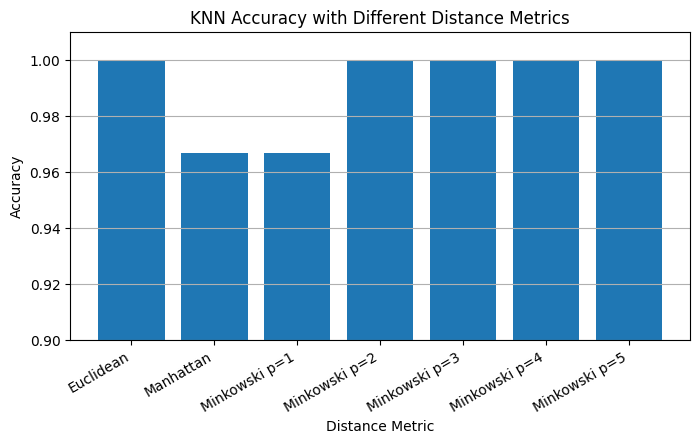

In [4]:
distance_configs = [
    ("Euclidean", "euclidean", 2),
    ("Manhattan", "manhattan", 1),
    ("Minkowski p=1", "minkowski", 1),
    ("Minkowski p=2", "minkowski", 2),
    ("Minkowski p=3", "minkowski", 3),
    ("Minkowski p=4", "minkowski", 4),
    ("Minkowski p=5", "minkowski", 5),
]

distance_rows = []

for name, metric, p in distance_configs:
    y_pred = knn_predict(X_train, y_train, X_test, k=best_k, metric=metric, p=p)
    distance_rows.append({
        "Distance Metric": name,
        "p": p,
        "k": best_k,
        "Accuracy": accuracy(y_test, y_pred)
    })

distance_results = pd.DataFrame(distance_rows)
display(distance_results.round(4))

plt.figure(figsize=(8, 4))
plt.bar(distance_results["Distance Metric"], distance_results["Accuracy"])
plt.xlabel("Distance Metric")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy with Different Distance Metrics")
plt.ylim(0.9, 1.01)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y")
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>تفسیر معیارهای فاصله</h3>

<p>
طبق جدول بالا، فاصله اقلیدسی و حالت‌های <span dir='ltr'>Minkowski</span> با <span dir='ltr'>p=2</span>، <span dir='ltr'>p=3</span>، <span dir='ltr'>p=4</span> و <span dir='ltr'>p=5</span> در این اجرا دقت <span dir='ltr'>1.0000</span> گرفتن. فاصله منهتن و <span dir='ltr'>Minkowski p=1</span> هم دقت <span dir='ltr'>0.9667</span> داشتن که همچنان نتیجه خوبی محسوب میشه.
</p>

<p>
این نتیجه نشان میده که بعد از نرمال‌سازی، چند معیار فاصله مختلف توانستن کلاس‌های دیتاست <span dir='ltr'>Iris</span> را خوب از هم جدا کنن. با این حال، انتخاب معیار فاصله همچنان مهمه، چون معیار فاصله تعیین می‌کنه کدام نمونه‌ها به عنوان نزدیک‌ترین همسایه انتخاب بشن.
</p>

<p>
در این داده، تفاوت معیارها خیلی زیاد نبوده، چون کلاس‌های <span dir='ltr'>Iris</span> نسبتا از هم جدا هستن. اما در داده‌های پیچیده‌تر یا داده‌هایی که ویژگی‌ها وابستگی‌های متفاوتی دارن، انتخاب معیار فاصله می‌تونه اثر بیشتری روی دقت مدل داشته باشه.
</p>

</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۵. جمع‌بندی</h3>

<p>
در این تمرین، الگوریتم <span dir='ltr'>KNN</span> از پایه پیاده‌سازی شد و برای چند مقدار مختلف <span dir='ltr'>k</span> روی دیتاست <span dir='ltr'>Iris</span> آزمایش شد. فاصله اقلیدسی و مرحله رای‌گیری به صورت دستی پیاده‌سازی شدن و دقت مدل برای مقدارهای مختلف <span dir='ltr'>k</span> گزارش شد.
</p>

<p>
نتیجه‌ها نشان دادن که مقدار <span dir='ltr'>k</span> روی عملکرد مدل اثر دارد و در این اجرا مقدار <span dir='ltr'>5</span> بهترین نتیجه را داده. همچنین مدل دستی با مدل آماده <span dir='ltr'>Scikit-Learn</span> مقایسه شد و در این تقسیم داده، پیش‌بینی‌های دو روش یکسان بودن.
</p>

<p>
در بخش آخر هم معیارهای فاصله مختلف بررسی شدن. نتیجه نشان داد که فاصله اقلیدسی و چند حالت از فاصله مینکوفسکی بهترین دقت را داشتن، اما فاصله منهتن هم عملکرد قابل قبولی داشت. به طور کلی، نرمال‌سازی داده‌ها و انتخاب مناسب <span dir='ltr'>k</span> و معیار فاصله برای عملکرد <span dir='ltr'>KNN</span> خیلی مهمه.
</p>

</div>